In [1]:
!pip install torchxrayvision --no-deps -q
!pip install scikit-image nltk matplotlib -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 42.1 MB/s eta 0:00:00


In [2]:
import os
import sys
import json
import subprocess
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

EXPECTED_TOTAL_IMAGES_P10_P11 = 75216

print("[Phase 1/4] Fetching official metadata and CheXpert labels from MIMIC-CXR-JPG...")
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    PHYSIONET_USER = user_secrets.get_secret("PHYSIONET_USER")
    PHYSIONET_PASS = user_secrets.get_secret("PHYSIONET_PASS")
except Exception:
    PHYSIONET_USER = os.environ.get("PHYSIONET_USER", "")
    PHYSIONET_PASS = os.environ.get("PHYSIONET_PASS", "")

netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w", encoding="utf-8") as f:
    f.write(f"machine physionet.org\nlogin {PHYSIONET_USER}\npassword {PHYSIONET_PASS}\n")
os.chmod(netrc_path, 0o600)

metadata_files = [
    ("meta.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-metadata.csv.gz"),
    ("chexpert.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-chexpert.csv.gz"),
]

for target_name, url in metadata_files:
    if not os.path.exists(target_name):
        gz_name = f"{target_name}.gz"
        subprocess.run(f"wget -q --netrc -O {gz_name} {url}", shell=True, check=True)
        subprocess.run(f"gunzip -f {gz_name}", shell=True, check=True)

print("[Phase 2/4] Building unified index across attached image datasets...")
input_base = Path("/kaggle/input")
file_index = {}
impression_file_path = None

for root, _, files in os.walk(input_base):
    for f in files:
        full_path = os.path.join(root, f)
        if f in ["mimic_train_impressions.csv", "train_imp.csv"]:
            impression_file_path = full_path
        elif f.endswith(".jpg"):
            parts = full_path.split("/")
            rel_path = None
            for prefix in ("p10", "p11"):
                if prefix in parts:
                    idx = parts.index(prefix)
                    rel_path = "/".join(parts[idx:])
                    break
            if rel_path is not None and rel_path not in file_index:
                file_index[rel_path] = full_path

print(f"Total unique images indexed: {len(file_index):,}")

if not impression_file_path:
    sys.exit("Error: mimic_train_impressions.csv not found in /kaggle/input/. Please attach the impression dataset.")

print("[Phase 3/4] Merging metadata, CheXpert labels, and report text...")
report_df = pd.read_csv(impression_file_path)
meta_df = pd.read_csv("meta.csv")
chex_df = pd.read_csv("chexpert.csv")

mask_cohort = (meta_df["subject_id"] >= 10000000) & (meta_df["subject_id"] < 12000000)
meta_cohort = meta_df[mask_cohort].copy()

label_cols = [c for c in chex_df.columns if c not in ["subject_id", "study_id"]]
merged_df = pd.merge(meta_cohort, chex_df[["study_id"] + label_cols], on="study_id", how="inner")
merged_df = pd.merge(merged_df, report_df[["dicom_id", "report"]], on="dicom_id", how="left")
merged_df = merged_df.dropna(subset=["report"]).reset_index(drop=True)

def get_path(row):
    subject_id = int(row["subject_id"])
    study_id = int(row["study_id"])
    prefix = "p10" if subject_id < 11000000 else "p11"
    rel = f"{prefix}/p{subject_id}/s{study_id}/{row['dicom_id']}.jpg"
    return file_index.get(rel, None)

merged_df["image_path"] = merged_df.apply(get_path, axis=1)
merged_df = merged_df.dropna(subset=["image_path"]).reset_index(drop=True)

print("[Phase 4/4] Executing strict patient-level split (0% leakage, seed=42)...")
np.random.seed(42)
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, temp_idx = next(gss_train.split(merged_df, groups=merged_df["subject_id"]))

train_df = merged_df.iloc[train_idx].copy()
temp_df = merged_df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["subject_id"]))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

master_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
master_df.to_csv("/kaggle/working/mimic_master_split.csv", index=False)

print(f"\nManifest Ready: Train={len(train_df):,} | Val={len(val_df):,} | Test={len(test_df):,}")
print("Saved to: /kaggle/working/mimic_master_split.csv")

[Phase 1/4] Fetching official metadata and CheXpert labels from MIMIC-CXR-JPG...
[Phase 2/4] Building unified index across attached image datasets...
Total unique images indexed: 73,995
[Phase 3/4] Merging metadata, CheXpert labels, and report text...
[Phase 4/4] Executing strict patient-level split (0% leakage, seed=42)...

Manifest Ready: Train=50,616 | Val=6,103 | Test=5,731
Saved to: /kaggle/working/mimic_master_split.csv


Using compute device: cuda
Loading manifest from: /kaggle/working/mimic_master_split.csv


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (17 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 382/382 [04:16<00:00,  1.49it/s]



--- Epoch 9 Summary ---
Loss   : Train = 1.2695 | Val = 1.6149
GATE 1 : BLEU-1 = 0.3062 (Target >= 0.25) | Distinct-2 = 0.1446 (Target >= 0.15)
--------------------------------------------------
>>> Resumable & Best Checkpoints Saved Successfully! <<<


Epoch 10/10 [Val]: 100%|██████████| 382/382 [04:16<00:00,  1.49it/s]



--- Epoch 10 Summary ---
Loss   : Train = 1.2216 | Val = 1.6138
GATE 1 : BLEU-1 = 0.3009 (Target >= 0.25) | Distinct-2 = 0.1736 (Target >= 0.15)
--------------------------------------------------
>>> Resumable & Best Checkpoints Saved Successfully! <<<


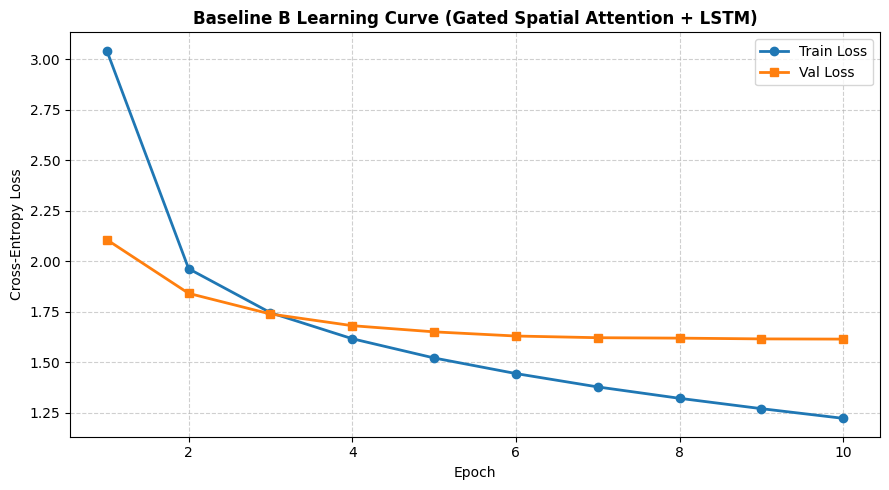

Learning curve plot saved to: /kaggle/working/baseline_b_learning_curve.png


In [3]:
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from tqdm import tqdm
import torchxrayvision as xrv
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams

# -------------------------------------------------------------------------
# 0. Global Seed & Hardware Configuration
# -------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

# -------------------------------------------------------------------------
# 1. Dataset & Tokenizer Setup
# -------------------------------------------------------------------------
manifest_path = "/kaggle/working/mimic_master_split.csv"
if not os.path.exists(manifest_path):
    import subprocess
    res = subprocess.run("find /kaggle/input -name 'mimic_master_split.csv' 2>/dev/null", shell=True, capture_output=True, text=True)
    paths = res.stdout.strip().split("\n")
    if paths and paths[0]:
        manifest_path = paths[0]

print(f"Loading manifest from: {manifest_path}")
master_df = pd.read_csv(manifest_path)

tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>"}
tokenizer.add_special_tokens(special_tokens)
vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id
bos_id = tokenizer.bos_token_id
eos_id = tokenizer.eos_token_id

class BaselineDataset(Dataset):
    def __init__(self, df, tokenizer, max_seq_len=100):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            img = Image.open(row['image_path']).convert('L').resize((224, 224))
            img_np = np.array(img, dtype=np.float32)
            img_normalized = xrv.datasets.normalize(img_np, maxval=255)
            image_tensor = torch.tensor(img_normalized, dtype=torch.float32).unsqueeze(0)
        except Exception:
            image_tensor = torch.zeros((1, 224, 224), dtype=torch.float32)

        report_text = str(row['report']) if pd.notna(row['report']) else ""
        tokenized = self.tokenizer(
            f"<bos> {report_text} <eos>",
            max_length=self.max_seq_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "image": image_tensor,
            "input_ids": tokenized["input_ids"].squeeze(0)
        }

train_df = master_df[master_df['split'] == 'train']
val_df   = master_df[master_df['split'] == 'val']
test_df  = master_df[master_df['split'] == 'test']

train_dataset = BaselineDataset(train_df, tokenizer, max_seq_len=100)
val_dataset   = BaselineDataset(val_df, tokenizer, max_seq_len=100)
test_dataset  = BaselineDataset(test_df, tokenizer, max_seq_len=100)

BATCH_SIZE = 16
ACCUMULATION_STEPS = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"DataLoaders Ready (Effective Batch Size = {BATCH_SIZE * ACCUMULATION_STEPS}):")
print(f"  Train : {len(train_loader):,} batches | Val : {len(val_loader):,} batches | Test : {len(test_loader):,} batches")

# -------------------------------------------------------------------------
# 2. Gate 1 Live Metric Calculator
# -------------------------------------------------------------------------
def calculate_gate1_metrics(predictions, references):
    smooth = SmoothingFunction().method1
    bleu1_scores = []
    all_bigrams = []
    
    for pred, ref in zip(predictions, references):
        pred_tokens = pred.split()
        ref_tokens = ref.split()
        
        if len(pred_tokens) > 0 and len(ref_tokens) > 0:
            b1 = sentence_bleu([ref_tokens], pred_tokens, weights=(1, 0, 0, 0), smoothing_function=smooth)
            bleu1_scores.append(b1)
            
        bigrams = list(ngrams(pred_tokens, 2))
        all_bigrams.extend(bigrams)
        
    avg_bleu1 = np.mean(bleu1_scores) if bleu1_scores else 0.0
    distinct_2 = len(set(all_bigrams)) / len(all_bigrams) if len(all_bigrams) > 0 else 0.0
    return avg_bleu1, distinct_2

# -------------------------------------------------------------------------
# 3. Bahdanau Attention & Gated Architecture
# -------------------------------------------------------------------------
class BahdanauAttention(nn.Module):
    def __init__(self, encoder_dim=1024, hidden_dim=512, attention_dim=256):
        super().__init__()
        self.w_encoder = nn.Linear(encoder_dim, attention_dim)
        self.w_decoder = nn.Linear(hidden_dim, attention_dim)
        self.full_att  = nn.Linear(attention_dim, 1)

    def forward(self, encoder_features, decoder_hidden):
        att1 = self.w_encoder(encoder_features)
        att2 = self.w_decoder(decoder_hidden).unsqueeze(1)
        score = self.full_att(torch.tanh(att1 + att2)).squeeze(2)
        alpha = F.softmax(score, dim=1)
        context = (encoder_features * alpha.unsqueeze(2)).sum(dim=1)
        return context, alpha

class BaselineDenseNetAttentionLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=512, encoder_dim=1024, pad_token_id=0):
        super().__init__()
        self.vocab_size = vocab_size
        self.pad_token_id = pad_token_id
        self.hidden_dim = hidden_dim
        self.encoder_dim = encoder_dim
        
        densenet = xrv.models.DenseNet(weights="densenet121-res224-mimic_ch")
        self.encoder = densenet.features
        for param in self.encoder.parameters():
            param.requires_grad = False
            
        self.attention = BahdanauAttention(encoder_dim=encoder_dim, hidden_dim=hidden_dim, attention_dim=256)
        self.beta_gate = nn.Linear(hidden_dim, encoder_dim) # Correctly declared Gating layer
        
        self.init_h = nn.Linear(encoder_dim, hidden_dim)
        self.init_c = nn.Linear(encoder_dim, hidden_dim)
        
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_token_id)
        self.lstm_cell = nn.LSTMCell(embed_dim + encoder_dim, hidden_dim)
        self.fc_out    = nn.Linear(hidden_dim + encoder_dim, vocab_size)

    def extract_spatial_features(self, images):
        with torch.no_grad():
            features = self.encoder(images)
        return features.flatten(2).permute(0, 2, 1)

    def forward(self, images, input_ids):
        spatial_features = self.extract_spatial_features(images)
        mean_features = spatial_features.mean(dim=1)
        
        h = torch.tanh(self.init_h(mean_features))
        c = torch.tanh(self.init_c(mean_features))
        
        batch_size, seq_len = input_ids.shape
        inputs = input_ids[:, :-1]
        embeddings = self.embedding(inputs)
        
        outputs = []
        for t in range(seq_len - 1):
            context, _ = self.attention(spatial_features, h)
            gate = torch.sigmoid(self.beta_gate(h))
            gated_context = gate * context
            
            lstm_input = torch.cat([embeddings[:, t, :], gated_context], dim=1)
            h, c = self.lstm_cell(lstm_input, (h, c))
            logit = self.fc_out(torch.cat([h, gated_context], dim=1))
            outputs.append(logit.unsqueeze(1))
            
        return torch.cat(outputs, dim=1)

    @torch.no_grad()
    def batched_greedy_generate(self, images, max_len=60):
        self.eval()
        batch_size = images.size(0)
        
        spatial_features = self.extract_spatial_features(images)
        mean_features = spatial_features.mean(dim=1)
        
        h = torch.tanh(self.init_h(mean_features))
        c = torch.tanh(self.init_c(mean_features))
        
        current_tokens = torch.full((batch_size, 1), bos_id, device=images.device, dtype=torch.long)
        generated_tokens = [[] for _ in range(batch_size)]
        finished = torch.zeros(batch_size, dtype=torch.bool, device=images.device)
        
        for _ in range(max_len):
            context, _ = self.attention(spatial_features, h)
            gate = torch.sigmoid(self.beta_gate(h))
            gated_context = gate * context
            
            emb = self.embedding(current_tokens).squeeze(1)
            lstm_input = torch.cat([emb, gated_context], dim=1)
            
            h, c = self.lstm_cell(lstm_input, (h, c))
            logit = self.fc_out(torch.cat([h, gated_context], dim=1))
            
            next_tokens = logit.argmax(dim=-1)
            current_tokens = next_tokens.unsqueeze(1)
            
            for i in range(batch_size):
                if not finished[i]:
                    if next_tokens[i].item() == eos_id:
                        finished[i] = True
                    else:
                        generated_tokens[i].append(next_tokens[i].item())
                        
            if finished.all():
                break
                
        return generated_tokens

# -------------------------------------------------------------------------
# 4. Model Initialization & Resumable Checkpoint Setup
# -------------------------------------------------------------------------
model = BaselineDenseNetAttentionLSTM(vocab_size=vocab_size, pad_token_id=pad_id).to(device)
optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss(ignore_index=pad_id)
scaler = torch.amp.GradScaler("cuda")

checkpoint_path = "/kaggle/working/baseline_b_resumable.pt"
start_epoch = 1
best_val_loss = float('inf')

if os.path.exists(checkpoint_path):
    print(f"Resuming training from {checkpoint_path}...")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state'])
    optimizer.load_state_dict(checkpoint['optimizer_state'])
    scheduler.load_state_dict(checkpoint['scheduler_state'])
    scaler.load_state_dict(checkpoint['scaler_state'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    print(f"Successfully resumed at Epoch {start_epoch} with Best Val Loss: {best_val_loss:.4f}")

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Baseline B Initialized. Trainable Parameters: {trainable_params:,}")

# -------------------------------------------------------------------------
# 5. Robust Training Loop with Live Gate 1 Metrics
# -------------------------------------------------------------------------
EPOCHS = 10
train_losses = []
val_losses = []

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    total_train_loss = 0.0
    optimizer.zero_grad()
    
    loop = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]")
    for i, batch in enumerate(loop):
        images = batch["image"].to(device, non_blocking=True)
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        targets = input_ids[:, 1:].contiguous()
        
        try:
            with torch.amp.autocast("cuda"):
                logits = model(images, input_ids)
                loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss = loss / ACCUMULATION_STEPS
                
            scaler.scale(loss).backward()
            
            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                
            total_train_loss += loss.item() * ACCUMULATION_STEPS
            loop.set_postfix(loss=f"{loss.item() * ACCUMULATION_STEPS:.4f}")
            
        except RuntimeError as e:
            if "out of memory" in str(e):
                print(f"\n[WARNING] OOM at batch {i}. Clearing cache and skipping batch.")
                torch.cuda.empty_cache()
                optimizer.zero_grad()
                continue
            else:
                raise e
                
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # Validation & Gate 1 Monitoring
    model.eval()
    total_val_loss = 0.0
    all_val_preds = []
    all_val_refs = []
    
    val_loop = tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]")
    with torch.no_grad():
        for batch in val_loop:
            images = batch["image"].to(device)
            input_ids = batch["input_ids"].to(device)
            targets = input_ids[:, 1:].contiguous()
            
            with torch.amp.autocast("cuda"):
                logits = model(images, input_ids)
                loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))
            total_val_loss += loss.item()
            
            if len(all_val_preds) < (20 * BATCH_SIZE):
                gen_ids = model.batched_greedy_generate(images, max_len=60)
                for b_idx in range(len(gen_ids)):
                    pred_str = tokenizer.decode(gen_ids[b_idx], skip_special_tokens=True)
                    ref_tokens = [t.item() for t in input_ids[b_idx] if t.item() not in (pad_id, bos_id, eos_id)]
                    ref_str = tokenizer.decode(ref_tokens, skip_special_tokens=True)
                    
                    all_val_preds.append(pred_str)
                    all_val_refs.append(ref_str)
            
    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    scheduler.step(avg_val_loss)
    
    val_bleu1, val_distinct2 = calculate_gate1_metrics(all_val_preds, all_val_refs)
    
    print(f"\n--- Epoch {epoch} Summary ---")
    print(f"Loss   : Train = {avg_train_loss:.4f} | Val = {avg_val_loss:.4f}")
    print(f"GATE 1 : BLEU-1 = {val_bleu1:.4f} (Target >= 0.25) | Distinct-2 = {val_distinct2:.4f} (Target >= 0.15)")
    print("-" * 50)
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        checkpoint = {
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(),
            'best_val_loss': best_val_loss
        }
        torch.save(checkpoint, checkpoint_path)
        # Also save lightweight state dict for evaluation pipeline
        torch.save(model.state_dict(), "/kaggle/working/baseline_b_best.pt")
        print(">>> Resumable & Best Checkpoints Saved Successfully! <<<")

# -------------------------------------------------------------------------
# 6. Plot Learning Curve
# -------------------------------------------------------------------------
if train_losses and val_losses:
    plt.figure(figsize=(9, 5))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', marker='o', linewidth=2)
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Val Loss', marker='s', linewidth=2)
    plt.title('Baseline B Learning Curve (Gated Spatial Attention + LSTM)', fontsize=12, fontweight='bold')
    plt.xlabel('Epoch', fontsize=10)
    plt.ylabel('Cross-Entropy Loss', fontsize=10)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    curve_path = "/kaggle/working/baseline_b_learning_curve.png"
    plt.savefig(curve_path, dpi=300)
    plt.show()
    print(f"Learning curve plot saved to: {curve_path}")

[Evaluation] Loading weights from: /kaggle/working/baseline_b_best.pt
Baseline B Checkpoint loaded successfully.

[Evaluation] Generating reports on 5,731 unseen test cases...


Evaluating Baseline B Test Set: 100%|██████████| 5731/5731 [12:40<00:00,  7.53it/s]



OVERALL BENCHMARK: Baseline B (DenseNet121 + Spatial Attention + LSTM)
Metric                         | Value
--------------------------------------------------
BLEU-1                         | 0.2981
BLEU-2                         | 0.2334
BLEU-3                         | 0.1964
BLEU-4                         | 0.1744
ROUGE-1                        | 0.3215
ROUGE-2                        | 0.2219
ROUGE-L                        | 0.3138
Clinical_Macro_F1              | 0.1721
Clinical_Micro_F1              | 0.3769
Clinical_Micro_Precision       | 0.4634
Clinical_Micro_Recall          | 0.3176

PER-PATHOLOGY CLINICAL BREAKDOWN: Baseline B
Pathology                  | TP    | FP    | FN    | TN    | Prec    | Recall  | F1     
-----------------------------------------------------------------------------------------------
Atelectasis                | 292   | 421   | 825   | 4193  | 0.4095  | 0.2614  | 0.3191 
Cardiomegaly               | 13    | 62    | 546   | 5110  | 0.1733  | 0.0233 

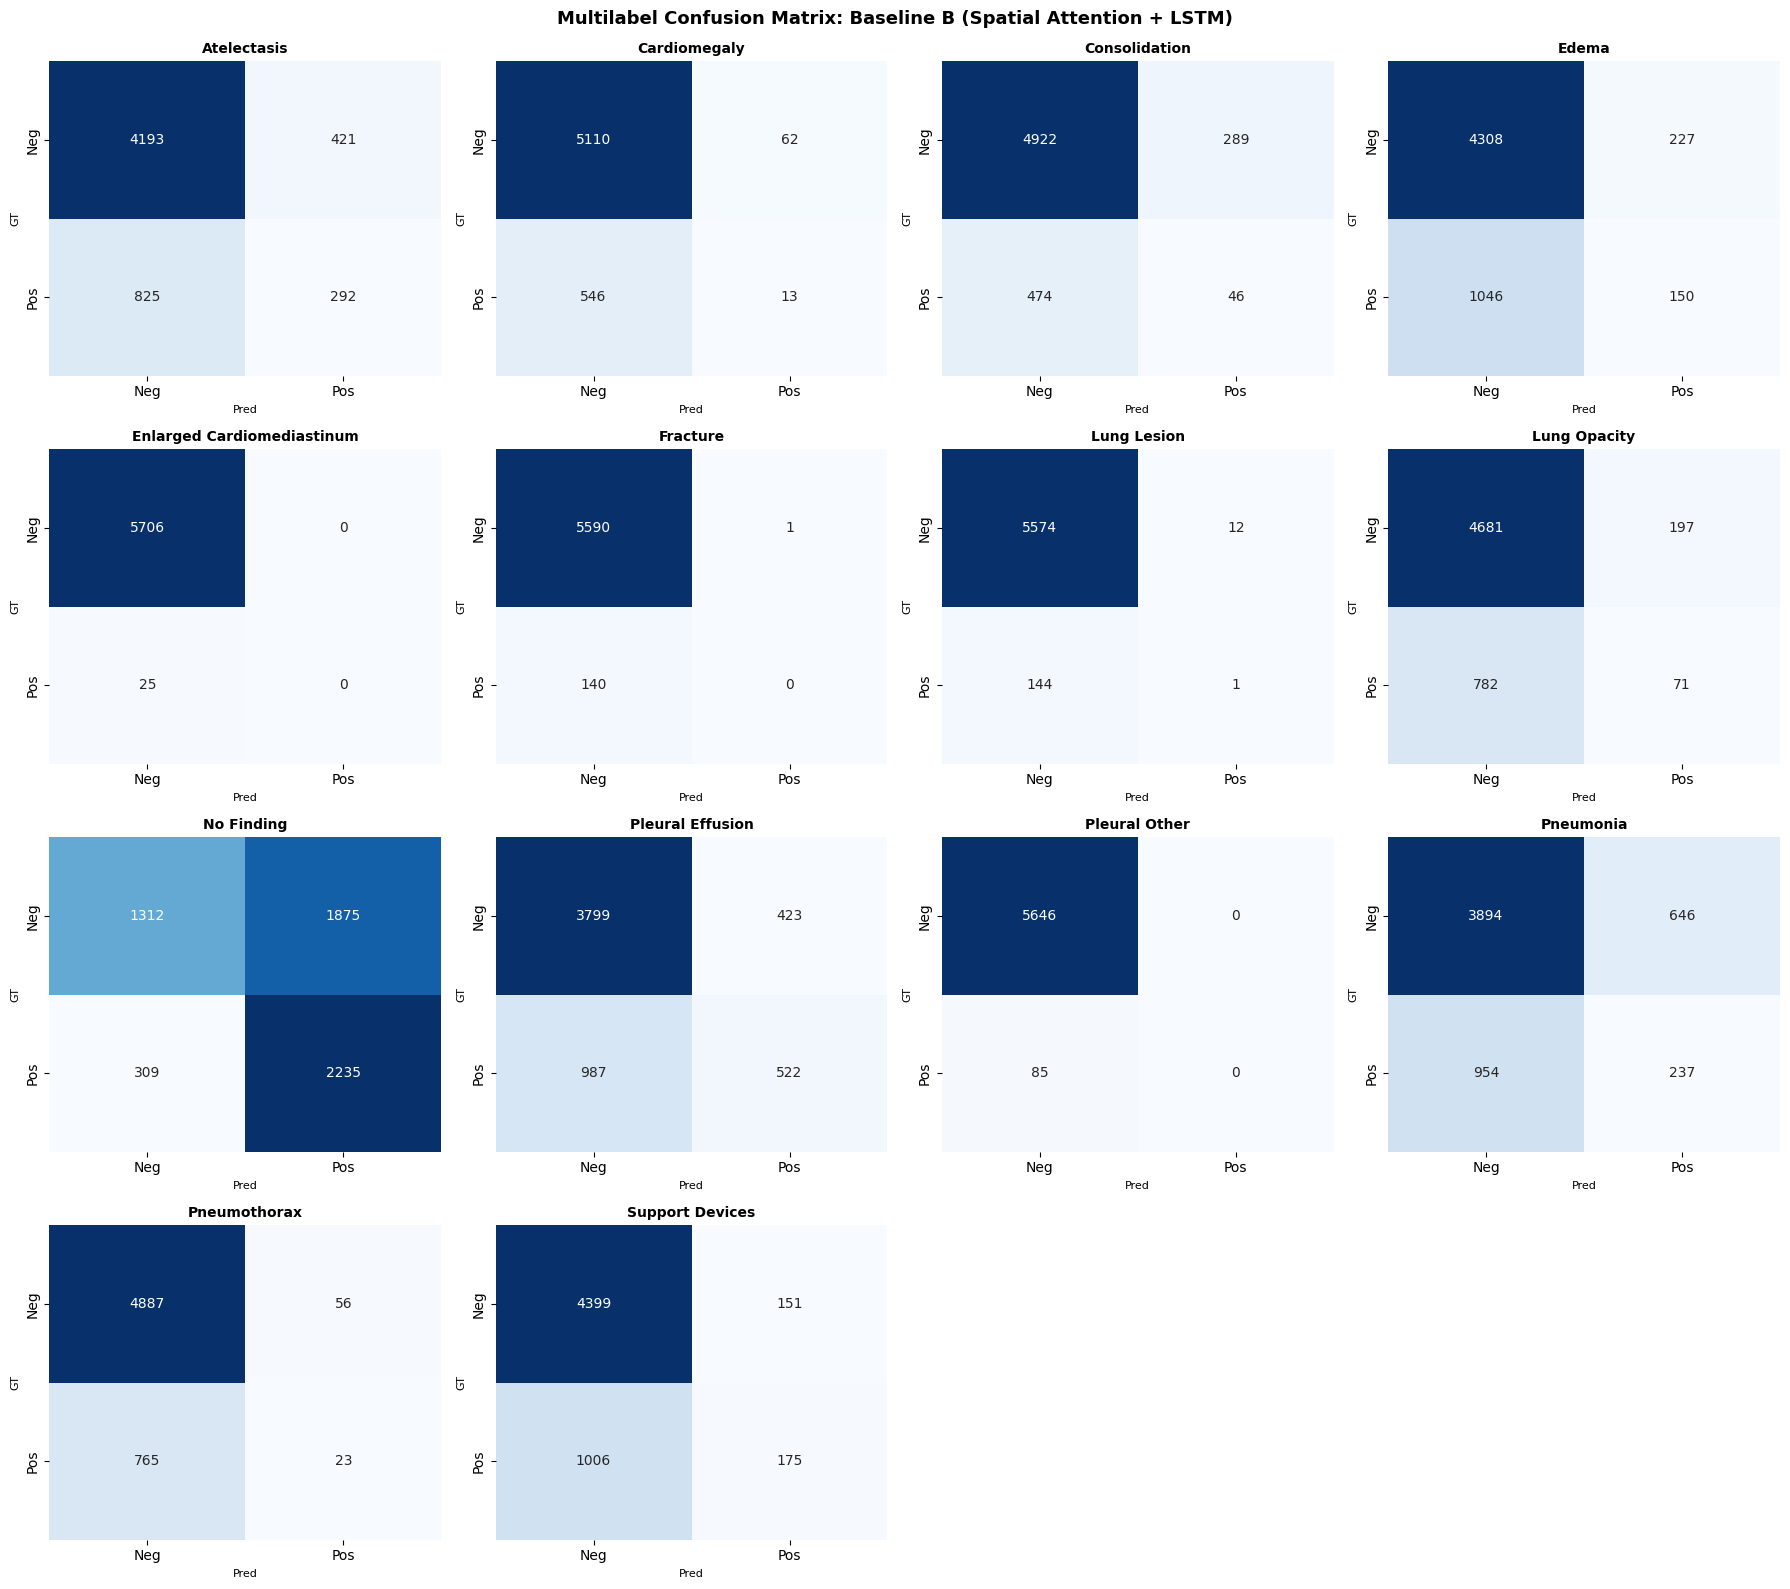


QUALITATIVE CASE STUDIES: Ground Truth vs Baseline B (Spatial Attention)

[Case #1 | Study ID: 52067803]
  Ground Truth: "Mild left base atelectasis. Otherwise, no acute cardiopulmonary process."
  Prediction  : "No acute cardiopulmonary process."
  BLEU-4=0.2466 | ROUGE-L=0.6154
--------------------------------------------------------------------------------

[Case #2 | Study ID: 52067803]
  Ground Truth: "Mild left base atelectasis. Otherwise, no acute cardiopulmonary process."
  Prediction  : "No acute cardiopulmonary process."
  BLEU-4=0.2466 | ROUGE-L=0.6154
--------------------------------------------------------------------------------

[Case #3 | Study ID: 50084553]
  Ground Truth: ", most _ _ _. Large right moderate left pleural effusions and severe bibasilar atelectasis unchanged. Cardiac silhouette is obscured. No pneumothorax. Pulmonary edema is mild, obscured radiographically by overlying abnormalities."
  Prediction  : "1. Right lower lobe pneumonia. 2. Small right pleur

In [4]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation for Metrics and Visualization
# -------------------------------------------------------------------------
!pip install rouge-score nltk seaborn matplotlib -q

import os
import json
import torch
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# -------------------------------------------------------------------------
# 1. Load Best Trained Model Checkpoint for Baseline B
# -------------------------------------------------------------------------
checkpoint_path = "/kaggle/working/baseline_b_best.pt"
if not os.path.exists(checkpoint_path):
    checkpoint_path = "/kaggle/working/baseline_b_resumable.pt"
    if os.path.exists(checkpoint_path):
        print(f"[Evaluation] Loading model state from resumable checkpoint...")
        ckpt = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
    else:
        raise FileNotFoundError("Baseline B checkpoint not found. Ensure training in Cell 3 completed.")
else:
    print(f"[Evaluation] Loading weights from: {checkpoint_path}")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

model.eval()
print("Baseline B Checkpoint loaded successfully.")

smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

# -------------------------------------------------------------------------
# 2. Run Generation Across All Test Set Instances
# -------------------------------------------------------------------------
print(f"\n[Evaluation] Generating reports on {len(test_dataset):,} unseen test cases...")

results = []
bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores = [], [], [], []
rouge1_scores, rouge2_scores, rougeL_scores = [], [], []
gt_pathology_matrix = []
pred_pathology_matrix = []

with torch.no_grad():
    for idx in tqdm(range(len(test_dataset)), desc="Evaluating Baseline B Test Set"):
        row = test_df.iloc[idx]
        image_tensor = test_dataset[idx]["image"].to(device)
        
        gen_tokens = model.batched_greedy_generate(image_tensor.unsqueeze(0), max_len=60)[0]
        pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        gt_text = str(row['report']).strip()
        
        ref_tokens = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
        hyp_tokens = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]
        
        b1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=smooth)
        b2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
        b3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
        b4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)
        
        rouge_res = rouge_evaluator.score(gt_text, pred_text)
        r1 = rouge_res['rouge1'].fmeasure
        r2 = rouge_res['rouge2'].fmeasure
        rL = rouge_res['rougeL'].fmeasure
        
        bleu1_scores.append(b1)
        bleu2_scores.append(b2)
        bleu3_scores.append(b3)
        bleu4_scores.append(b4)
        rouge1_scores.append(r1)
        rouge2_scores.append(r2)
        rougeL_scores.append(rL)
        
        gt_row_labels = []
        pred_row_labels = []
        for path_name, kws in clinical_keywords.items():
            gt_row_labels.append(int(any(kw in gt_text.lower() for kw in kws)))
            pred_row_labels.append(int(any(kw in pred_text.lower() for kw in kws)))
            
        gt_pathology_matrix.append(gt_row_labels)
        pred_pathology_matrix.append(pred_row_labels)
        
        results.append({
            "dicom_id": row["dicom_id"],
            "study_id": row["study_id"],
            "ground_truth": gt_text,
            "prediction": pred_text,
            "bleu1": round(b1, 4),
            "bleu4": round(b4, 4),
            "rougeL": round(rL, 4)
        })

# -------------------------------------------------------------------------
# 3. Overall Benchmark Metrics Summary
# -------------------------------------------------------------------------
gt_matrix = np.array(gt_pathology_matrix)
pred_matrix = np.array(pred_pathology_matrix)

micro_f1   = f1_score(gt_matrix, pred_matrix, average='micro', zero_division=0)
macro_f1   = f1_score(gt_matrix, pred_matrix, average='macro', zero_division=0)
micro_prec = precision_score(gt_matrix, pred_matrix, average='micro', zero_division=0)
micro_rec  = recall_score(gt_matrix, pred_matrix, average='micro', zero_division=0)

summary_metrics = {
    "Model": "Baseline B (DenseNet121 + Gated Spatial Attention + LSTM)",
    "Test_Samples": len(results),
    "BLEU-1": round(float(np.mean(bleu1_scores)), 4),
    "BLEU-2": round(float(np.mean(bleu2_scores)), 4),
    "BLEU-3": round(float(np.mean(bleu3_scores)), 4),
    "BLEU-4": round(float(np.mean(bleu4_scores)), 4),
    "ROUGE-1": round(float(np.mean(rouge1_scores)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_scores)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_scores)), 4),
    "Clinical_Macro_F1": round(float(macro_f1), 4),
    "Clinical_Micro_F1": round(float(micro_f1), 4),
    "Clinical_Micro_Precision": round(float(micro_prec), 4),
    "Clinical_Micro_Recall": round(float(micro_rec), 4)
}

print("\n" + "=" * 80)
print("OVERALL BENCHMARK: Baseline B (DenseNet121 + Spatial Attention + LSTM)")
print("=" * 80)
print(f"{'Metric':<30} | {'Value'}")
print("-" * 50)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"{k:<30} | {v}")
print("=" * 80)

# -------------------------------------------------------------------------
# 4. Per-Pathology Breakdown Table
# -------------------------------------------------------------------------
pathology_names = list(clinical_keywords.keys())
mcm = multilabel_confusion_matrix(gt_matrix, pred_matrix)
pathology_stats = []

print("\n" + "=" * 95)
print("PER-PATHOLOGY CLINICAL BREAKDOWN: Baseline B")
print("=" * 95)
print(f"{'Pathology':<26} | {'TP':<5} | {'FP':<5} | {'FN':<5} | {'TN':<5} | {'Prec':<7} | {'Recall':<7} | {'F1':<7}")
print("-" * 95)

for i, name in enumerate(pathology_names):
    tn, fp, fn, tp = mcm[i].ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    pathology_stats.append({
        "Pathology": name, "TP": int(tp), "FP": int(fp),
        "FN": int(fn), "TN": int(tn),
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1_Score": round(f1, 4)
    })
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f}")

print("=" * 95)

# -------------------------------------------------------------------------
# 5. 14-Panel Confusion Matrix Heatmap Plot
# -------------------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, name in enumerate(pathology_names):
    sns.heatmap(
        mcm[i], annot=True, fmt="d", cmap="Blues", cbar=False,
        ax=axes[i], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"]
    )
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_ylabel("GT", fontsize=8)
    axes[i].set_xlabel("Pred", fontsize=8)

for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Multilabel Confusion Matrix: Baseline B (Spatial Attention + LSTM)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("/kaggle/working/baseline_b_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------------------------------------------------
# 6. Qualitative Case Studies (5 Examples)
# -------------------------------------------------------------------------
print("\n" + "=" * 80)
print("QUALITATIVE CASE STUDIES: Ground Truth vs Baseline B (Spatial Attention)")
print("=" * 80)
for i in range(min(5, len(results))):
    print(f"\n[Case #{i+1} | Study ID: {results[i]['study_id']}]")
    print(f"  Ground Truth: \"{results[i]['ground_truth']}\"")
    print(f"  Prediction  : \"{results[i]['prediction']}\"")
    print(f"  BLEU-4={results[i]['bleu4']} | ROUGE-L={results[i]['rougeL']}")
    print("-" * 80)

# -------------------------------------------------------------------------
# 7. Save Artifacts to Working Directory
# -------------------------------------------------------------------------
pd.DataFrame(results).to_csv("/kaggle/working/baseline_b_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv("/kaggle/working/baseline_b_pathology_breakdown.csv", index=False)
with open("/kaggle/working/baseline_b_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("\nBaseline B Evaluation artifacts saved successfully to /kaggle/working/")